## Feature Engineering + TF-IDF

Feature engineering:
- build numerical features
- number of links, email length, suspicious key words

TF-IDF:
- convert words in emails into numerical values so machine learning model can learn which words are useful for distinguishing phishing from legitimate emails

Deliverables:
classify if email is legitimate (0) or phishing/spam (1)

In [1]:
import re
import numpy as np
import pandas as pd 
from pathlib import Path


PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_emails.csv"

data_df = pd.read_csv(DATA_PATH)

print("Dataset shape:", data_df.shape)
display(data_df.head())

#display data
data_df

C:\Users\New User\AppData\Local\Temp\ipykernel_15980\491411028.py:14: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pd.read_csv(DATA_PATH)


Dataset shape: (216905, 19)


,sender,receiver,date,subject,body,label,urls,source_file,url_flag,url_list,url_count,url_unique_domains,url_max_length,url_has_ip,url_has_http_only,url_has_at_symbol,url_has_shortener,url_has_suspicious_word,url_max_subdomains
0,young esposito <young@iworld.de>,user4@gvc.ceas-challenge.cc,2008-08-05 23:31:02+00:00,never agree to be a loser,"buck up, your troubles caused by small dimensi...",1.0,1,CEAS_08.csv,1.0,http://whitedone.com/,1,1,21,0,1,0,0,0,1
1,mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,2008-08-05 23:31:03+00:00,befriend jenna jameson,upgrade your sex and pleasures with these tech...,1.0,1,CEAS_08.csv,1.0,http://www.brightmade.com,1,1,25,0,1,0,0,0,2
2,daily top 10 <karmandeep-opengevl@universalnet...,user2.9@gvc.ceas-challenge.cc,2008-08-06 08:28:00+00:00,cnn.com daily top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1.0,1,CEAS_08.csv,1.0,http://www.cnn.com/video/partners/email/index....,24,2,114,0,1,1,0,0,2
3,michael parker <ivqrnai@pobox.com>,spamassassin dev <xrh@spamassassin.apache.org>,2008-08-05 23:31:20+00:00,re: svn commit: r619753 - in /spamassassin/tru...,would anyone object to removing .so from this ...,0.0,1,CEAS_08.csv,1.0,http://en.wikipedia.org/wiki/.so_%28domain_nam...,602,596,138,0,1,0,0,0,2
4,gretchen suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,2008-08-05 23:31:21+00:00,specialpricespharmmoreinfo,welcomefastshippingcustomersupport http://7iwf...,1.0,1,CEAS_08.csv,1.0,http://7iwfna.blu.livefilestore.com/y1pxdx3kwz...,1,1,136,0,1,0,0,0,3


,sender,receiver,date,subject,body,label,urls,source_file,url_flag,url_list,url_count,url_unique_domains,url_max_length,url_has_ip,url_has_http_only,url_has_at_symbol,url_has_shortener,url_has_suspicious_word,url_max_subdomains
0,young esposito <young@iworld.de>,user4@gvc.ceas-challenge.cc,2008-08-05 23:31:02+00:00,never agree to be a loser,"buck up, your troubles caused by small dimensi...",1.0,1,CEAS_08.csv,1.0,http://whitedone.com/,1,1,21,0,1,0,0,0,1
1,mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,2008-08-05 23:31:03+00:00,befriend jenna jameson,upgrade your sex and pleasures with these tech...,1.0,1,CEAS_08.csv,1.0,http://www.brightmade.com,1,1,25,0,1,0,0,0,2
2,daily top 10 <karmandeep-opengevl@universalnet...,user2.9@gvc.ceas-challenge.cc,2008-08-06 08:28:00+00:00,cnn.com daily top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1.0,1,CEAS_08.csv,1.0,http://www.cnn.com/video/partners/email/index....,24,2,114,0,1,1,0,0,2
3,michael parker <ivqrnai@pobox.com>,spamassassin dev <xrh@spamassassin.apache.org>,2008-08-05 23:31:20+00:00,re: svn commit: r619753 - in /spamassassin/tru...,would anyone object to removing .so from this ...,0.0,1,CEAS_08.csv,1.0,http://en.wikipedia.org/wiki/.so_%28domain_nam...,602,596,138,0,1,0,0,0,2
4,gretchen suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,2008-08-05 23:31:21+00:00,specialpricespharmmoreinfo,welcomefastshippingcustomersupport http://7iwf...,1.0,1,CEAS_08.csv,1.0,http://7iwfna.blu.livefilestore.com/y1pxdx3kwz...,1,1,136,0,1,0,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
216900,scc <gerry.rossi4360@kinki-kids.com>,deficient <deficient@flax9.uwaterloo.ca>,2007-07-06 10:53:36+00:00,job: just for you.,while we may have high expectations of our ass...,1.0,1,TREC_07.csv,1.0,http://vacancy-85953.centrecar.jp/vacancies.php,1,1,47,0,1,0,0,0,2
216901,sydney car centre <merrill8783@168city.com>,gnitpick <gnitpick@flax9.uwaterloo.ca>,2007-07-06 10:59:51+00:00,the reply for your request for a job place [le...,while we may have high expectations of our ass...,1.0,1,TREC_07.csv,1.0,http://vacancy-51148191.scc2007.hk/vacancies.php,1,1,48,0,1,0,0,0,2
216902,philippe grosjean <phgrosjean@sciviews.org>,duncan murdoch <murdoch@stats.uwo.ca>,2007-07-06 10:57:17+00:00,"re: [r] me again, about the horrible documenta...","for those who are interested, i just cook a li...",0.0,1,TREC_07.csv,1.0,http://wiki.r-project.org/rwiki/doku.php?id=rd...,4,4,65,0,1,0,0,0,2
216903,bernhard wellhöfer <bernhard.wellhoefer@gaia-g...,r-help@stat.math.ethz.ch,2007-07-06 10:43:12+00:00,re: [r] rodbc problem,"hello, as i wrote i call sqlfetch(channel,""t_s...",0.0,1,TREC_07.csv,1.0,https://stat.ethz.ch/mailman/listinfo/r-help h...,2,2,44,0,1,0,0,0,2


In [2]:
#inspect existing columns
print(data_df.columns)

Index(['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls',
       'source_file', 'url_flag', 'url_list', 'url_count',
       'url_unique_domains', 'url_max_length', 'url_has_ip',
       'url_has_http_only', 'url_has_at_symbol', 'url_has_shortener',
       'url_has_suspicious_word', 'url_max_subdomains'],
      dtype='object')


In [3]:
#check count for each email type
# 0 - legit
# 1 - phish/spam

print(data_df["label"].value_counts(dropna=False))
print(data_df["label"].dtype)

#check missing labels
print("\n\nMissing labels:", data_df["label"].isna().sum())

label
0.0    112858
1.0    104047
Name: count, dtype: int64
float64


Missing labels: 0


## Feature Engineering

### Email Length
- subject length: number of characters in subject
- body length: number of characters in the body
- total length: combined subject and body

In [4]:
data_df["subject_length"] = data_df["subject"].str.len()

data_df["body_length"] = data_df["body"].str.len()

data_df["total_length"] = (data_df["subject_length"] + data_df["body_length"])


data_df[["subject", "subject_length", "body_length", "total_length"]].head()

,subject,subject_length,body_length,total_length
0,never agree to be a loser,25.0,271.0,296.0
1,befriend jenna jameson,22.0,78.0,100.0
2,cnn.com daily top 10,20.0,3655.0,3675.0
3,re: svn commit: r619753 - in /spamassassin/tru...,150.0,24195.0,24345.0
4,specialpricespharmmoreinfo,26.0,171.0,197.0


### Word Count

In [5]:
# search for every word like sequence
# \b - word boundaries
# \w+ - matches one or more word characters
def count_words(text):
    return len(re.findall(r"\b\w+\b", str(text))) 

data_df["subject_word_count"] = (
    data_df["subject"].apply(count_words)
)

data_df["body_word_count"] = (
    data_df["body"].apply(count_words)
)

data_df["total_word_count"] = (
    data_df["subject_word_count"] +
    data_df["body_word_count"]
)

data_df[["subject", "subject_word_count", "body_word_count", "total_word_count"]].head()

,subject,subject_word_count,body_word_count,total_word_count
0,never agree to be a loser,6,49,55
1,befriend jenna jameson,3,12,15
2,cnn.com daily top 10,5,629,634
3,re: svn commit: r619753 - in /spamassassin/tru...,21,3952,3973
4,specialpricespharmmoreinfo,1,11,12


### Suspicious keyword counts

In [6]:
# define suspicious words
SUSPICIOUS_KEYWORDS = [
    "verify",
    "account",
    "password",
    "login",
    "urgent",
    "suspended",
    "payment",
    "confirm",
    "security",
    "click",
    "bank",
    "update",
    "limited",
    "immediately",
    "credit"
]

def count_suspicious_words(text):
    text = str(text).lower()

    count = 0

    for word in SUSPICIOUS_KEYWORDS:
        pattern = rf"\b{re.escape(word)}\b"
        count += len(re.findall(pattern, text))

    return count


data_df["suspicious_word_count"] = (
    data_df["subject"] + " " + data_df["body"]
).apply(count_suspicious_words)


data_df[["subject", "suspicious_word_count", "label"]].head(10)

,subject,suspicious_word_count,label
0,never agree to be a loser,0,1.0
1,befriend jenna jameson,0,1.0
2,cnn.com daily top 10,0,1.0
3,re: svn commit: r619753 - in /spamassassin/tru...,1,0.0
4,specialpricespharmmoreinfo,0,1.0
5,from caroline aragon,0,1.0
6,replica watches,0,1.0
7,cnn.com daily top 10,0,1.0
8,[bug 5780] uri processing turns uuencoded stri...,0,0.0
9,cnn.com daily top 10,0,1.0


### Symbol / numberical features

other potentially useful characteristics
count of:
- exclamation marks
- question marks
- digits
- dollar signs

In [ ]:
combined_text = data_df["subject"] + " " + data_df["body"]

data_df["exclamation_count"] = (
    combined_text.str.count("!")
)

data_df["question_count"] = (
    combined_text.str.count(r"\?")

)

data_df["digit_count"] = (
    combined_text.str.count(r"\d")
)

data_df["dollar_count"] = (
    combined_text.str.count(r"\$")
)

### All Engineered Features

In [ ]:
engineered_features = [ #used later when combined with TF-IDF
    "subject_length",
    "body_length",
    "total_length",
    "subject_word_count",
    "body_word_count",
    "total_word_count",
    "suspicious_word_count",
    "exclamation_count",
    "question_count",
    "digit_count",
    "dollar_count",
    "url_count",
    "url_unique_domains",
    "url_has_ip",
    "url_has_http_only",
    "url_has_at_symbol",
    "url_has_shortener",
    "url_has_suspicious_word"
]

display(data_df[engineered_features].describe().round(2))

,subject_length,body_length,total_length,subject_word_count,body_word_count,total_word_count,suspicious_word_count,exclamation_count,question_count,digit_count,dollar_count,url_count,url_unique_domains,url_has_ip,url_has_http_only,url_has_at_symbol,url_has_shortener,url_has_suspicious_word
count,214292.00,216887.00,214274.00,216905.00,216905.00,216905.00,216905.00,214274.00,214274.00,214274.00,214274.00,216905.00,216905.00,216905.00,216905.00,216905.00,216905.00,216905.00
mean,35.95,1777.89,1810.80,5.90,283.79,289.69,1.13,1.36,1.53,67.92,1.50,1.31,0.71,0.00,0.40,0.02,0.00,0.01
std,30.07,17896.85,17661.09,5.58,1901.32,1901.38,8.46,8.57,15.45,2369.28,11.12,8.52,5.91,0.04,0.49,0.15,0.02,0.11
min,1.00,1.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,20.00,350.00,384.00,3.00,57.00,63.00,0.00,0.00,0.00,4.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,32.00,779.00,822.00,5.00,132.00,138.00,0.00,0.00,0.00,17.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,46.00,1782.00,1826.00,8.00,295.00,301.00,1.00,1.00,1.00,44.00,0.00,1.00,1.00,0.00,1.00,0.00,0.00,0.00
max,7169.00,4557647.00,4557696.00,1660.00,433412.00,433417.00,2406.00,1879.00,3188.00,740182.00,1685.00,3134.00,2398.00,1.00,1.00,1.00,1.00,1.00


# TF-IDF Implementation

TF - Term Frequency
IDF - Inverse Document Frequency

#### Combined measurements assign a weight to a word


TF = word occurrences / total words

IDF = log(N/df(t))
    
     (N=total number of documents, df(t)=number of documents containing the word)

In [9]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

#combine subject and body
data_df["text_combined"] = (
    data_df["subject"].fillna("") + " " +
    data_df["body"].fillna("")
)

display(data_df[["subject", "body", "text_combined"]].head())

,subject,body,text_combined
0,never agree to be a loser,"buck up, your troubles caused by small dimensi...","never agree to be a loser buck up, your troubl..."
1,befriend jenna jameson,upgrade your sex and pleasures with these tech...,befriend jenna jameson upgrade your sex and pl...
2,cnn.com daily top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,cnn.com daily top 10 >+=+=+=+=+=+=+=+=+=+=+=+=...
3,re: svn commit: r619753 - in /spamassassin/tru...,would anyone object to removing .so from this ...,re: svn commit: r619753 - in /spamassassin/tru...
4,specialpricespharmmoreinfo,welcomefastshippingcustomersupport http://7iwf...,specialpricespharmmoreinfo welcomefastshipping...


In [12]:
#create vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",       #removes common english words
    max_features=50000,         #limits vocab size
    ngram_range=(1, 2),         #word combinations
    min_df=2,                   #minimum document frequency (ignores words appearing in fewer than 2 emails)
    max_df=0.95,                #ignores words in more than 95% of emails
    sublinear_tf=True           #adjusts term frequency (reduces influence of repeated words)
)

##### n-gram is a sequence of consecutive words

Unigrams - one word
- ex. verify

Bigrams - two consecutive words
- ex. verify your

### Split dataset before TF-IDF
- allow vectorization to learn vocabulary and document frequencies from documents it is fitted on
- prevents data leakage

In [13]:
from sklearn.model_selection import train_test_split

X = data_df["text_combined"]

y = data_df["label"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

Training emails: 173524
Testing emails: 43381


In [15]:
# fit Tf-IDF
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)


# training
# learns and converts training emails to TF-IDF vectors
tfidf.fit_transform(X_train)


# testing
# converts test emails using vocab and IDF weights learned from training
tfidf.transform(X_test)


print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

print("Vocabulary size:", len(tfidf.vocabulary_))

Training matrix shape: (173524, 50000)
Testing matrix shape: (43381, 50000)
Vocabulary size: 50000


In [16]:
# see actual vocab
feature_names = tfidf.get_feature_names_out()

print("First 50 features:")
print(feature_names[:50])

First 50 features:
['00' '00 00' '00 0000' '00 01' '00 02' '00 03' '00 04' '00 05' '00 0500'
 '00 06' '00 07' '00 0700' '00 08' '00 09' '00 0e' '00 10' '00 11' '00 12'
 '00 129' '00 13' '00 14' '00 149' '00 15' '00 16' '00 17' '00 18' '00 19'
 '00 20' '00 2000' '00 21' '00 22' '00 23' '00 24' '00 25' '00 26'
 '00 2600' '00 269' '00 27' '00 28' '00 29' '00 2900' '00 30' '00 31'
 '00 32' '00 33' '00 34' '00 35' '00 36' '00 40' '00 416']


### Combine engineered features + TF-IDF

- X_train_tfidf: text converted into numerical features
- Structured features: email lengths, suspicious word counts, URL information, punctuation, etc.

In [17]:
from sklearn.impute import SimpleImputer

X_structured = data_df[engineered_features].copy()

# replace infinite values, if any
X_structured = X_structured.replace(
    [np.inf, -np.inf], np.nan
)

X_structured_train = X_structured.loc[X_train.index]
X_structured_test = X_structured.loc[X_test.index]

# learn missing-value replacements from training data only
imputer = SimpleImputer(strategy="median")

X_structured_train = imputer.fit_transform(
    X_structured_train
)

X_structured_test = imputer.transform(
    X_structured_test
)

Training Emails: 173,524

Testing Emails: 43,381

Total Features: 50,018

Class Distribution: 
- 52% legit in both training/testing
- 48 % phishing in both training/testing

In [18]:
#combine matrices 
from scipy.sparse import hstack, csr_matrix

X_train_combined = hstack([
    X_train_tfidf,
    csr_matrix(X_structured_train)
]).tocsr()

X_test_combined = hstack([
    X_test_tfidf,
    csr_matrix(X_structured_test)
]).tocsr()

print("Combined training shape:", X_train_combined.shape)
print("Combined testing shape:", X_test_combined.shape)

Combined training shape: (173524, 50018)
Combined testing shape: (43381, 50018)


In [19]:
print("Training:", X_train_combined.shape)
print("Testing:", X_test_combined.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training: (173524, 50018)
Testing: (43381, 50018)
Training labels: (173524,)
Testing labels: (43381,)


In [20]:
print("Training distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training distribution:
label
0    0.52
1    0.48
Name: proportion, dtype: float64

Testing distribution:
label
0    0.52
1    0.48
Name: proportion, dtype: float64


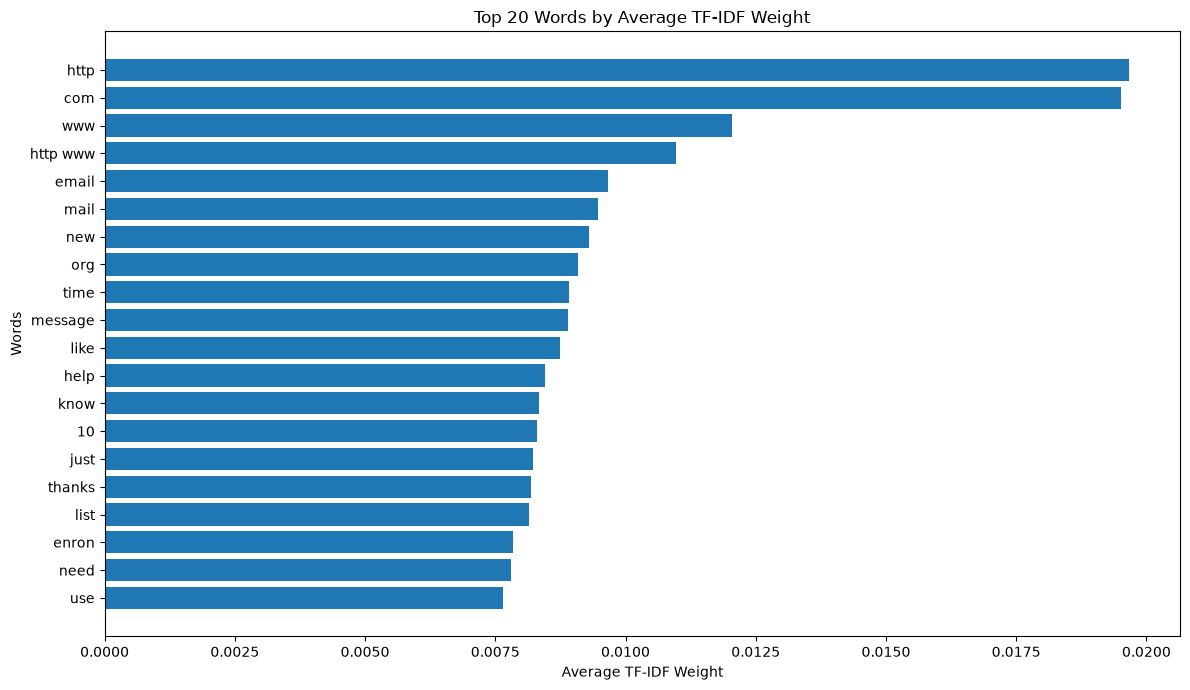

In [24]:
import matplotlib.pyplot as plt

mean_tfidf = np.asarray(
    X_train_tfidf.mean(axis=0)
).flatten()

top_indices = mean_tfidf.argsort()[-20:][::-1]

plt.figure(figsize=(12, 7))

plt.barh(
    feature_names[top_indices][::-1],
    mean_tfidf[top_indices][::-1]
)

plt.title("Top 20 Words by Average TF-IDF Weight")
plt.xlabel("Average TF-IDF Weight")
plt.ylabel("Words")

plt.tight_layout()
plt.show()